In [30]:
import json
import yaml
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path
from statistics import mean
import pandas as pd
from transformers.trainer_utils import get_last_checkpoint

def load_yaml(path):
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File tidak ditemukan: {filepath}")
    with open(filepath, "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}

def load_json(path):
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File JSON tidak ditemukan: {filepath}")
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

def get_loss_file(method_num: int, folder: str) -> Path:
    """Ambil trainer_state.json dari checkpoint terakhir."""
    output_dir = Path(f"{method_num}_outputs") / folder / "outputs"
    
    last_checkpoint = get_last_checkpoint(str(output_dir))
    
    if last_checkpoint:
        loss_file = Path(last_checkpoint) / "trainer_state.json"
    else:
        # Fallback: langsung di output_dir jika tidak ada checkpoint
        loss_file = output_dir / "trainer_state.json"
    
    return loss_file

def extract_loss_from_trainer_state(trainer_state: dict) -> dict:
    """
    Ekstrak semua jenis loss dari log_history di trainer_state.json.
    Mengembalikan dict berisi {loss_type: [(step, value), ...]}
    """
    log_history = trainer_state.get("log_history", [])
    print(log_history[0])
    loss_series = {}

    for entry in log_history:
        step = entry.get("step")
        for key, value in entry.items():
            if "loss" in key.lower() and isinstance(value, (int, float)):
                loss_series.setdefault(key, []).append((step, value))

    return loss_series

def plot_all_losses(method_num: int, save_path: str = "loss_plot.png"):
    method_cfg = load_yaml(f"configs/methods/{method_num}.yaml")
    experiments = method_cfg.get("experiments", [])

    # Kumpulkan folder output tiap eksperimen
    folder_map = {}  # folder -> label eksperimen
    for exp in experiments:
        exp_code = exp.get("code")
        if exp_code:
            exp_cfg = load_yaml(f"configs/experiments/{exp_code}")
            output_name = exp_cfg.get("output_name")
            label = exp_cfg.get("label", exp_code)  # fallback ke kode jika tidak ada label
            if output_name:
                folder_map[output_name] = label

    # Baca semua trainer_state.json dan kumpulkan data loss
    all_data = {}  # (folder_label, loss_type) -> [(step, value)]
    for folder, label in folder_map.items():
        loss_file = get_loss_file(method_num, folder)
        print(f"Membaca: {loss_file}")
        if not loss_file.is_file():
            print(f"  [SKIP] File tidak ditemukan.")
            continue

        trainer_state = load_json(loss_file)
        loss_series = extract_loss_from_trainer_state(trainer_state)

        for loss_type, values in loss_series.items():
            key = (label, loss_type)
            all_data[key] = values

    if not all_data:
        print("Tidak ada data loss yang ditemukan.")
        return

    # ── Plot ──────────────────────────────────────────────────────────────────
    loss_types = sorted(set(lt for _, lt in all_data.keys()))
    n_plots = len(loss_types)
    fig, axes = plt.subplots(n_plots, 1, figsize=(12, 4 * n_plots), squeeze=False)
    colors = cm.tab10.colors

    for ax_idx, loss_type in enumerate(loss_types):
        ax = axes[ax_idx][0]
        color_idx = 0

        for (label, lt), values in sorted(all_data.items()):
            if lt != loss_type:
                continue
            steps, losses = zip(*values)
            ax.plot(steps, losses,
                    label=label,
                    color=colors[color_idx % len(colors)],
                    linewidth=1.5,
                    alpha=0.85)
            color_idx += 1

        ax.set_title(loss_type.replace("_", " ").title(), fontsize=13, fontweight="bold")
        ax.set_xlabel("Step")
        ax.set_ylabel("Loss")
        ax.legend(loc="upper right", fontsize=8)
        ax.grid(True, linestyle="--", alpha=0.4)

    fig.suptitle(f"Loss Curves — Method {method_num}", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches="tight", dpi=150)
    print(f"\nPlot disimpan ke: {save_path}")
    plt.show()

    # ── Ringkasan DataFrame ───────────────────────────────────────────────────
    rows = []
    for (label, loss_type), values in all_data.items():
        _, losses = zip(*values)
        rows.append({
            "experiment": label,
            "loss_type": loss_type,
            "min": min(losses),
            "max": max(losses),
            "mean": mean(losses),
            "final": losses[-1],
            "n_steps": len(losses),
        })

    df = pd.DataFrame(rows).sort_values(["loss_type", "experiment"]).reset_index(drop=True)
    print("\nRingkasan Loss:")
    print(df.to_string(index=False))
    return df

Membaca: method6_outputs/qwen_5_warmup/outputs/checkpoint-570/trainer_state.json
{'epoch': 0.017787659811006114, 'grad_norm': 17.125, 'learning_rate': 0.0, 'loss': 1.7305065393447876, 'step': 1}
Membaca: method6_outputs/qwen_5_finetune/outputs/checkpoint-570/trainer_state.json
{'epoch': 0.017787659811006114, 'grad_norm': 29696.0, 'learning_rate': 0.0, 'loss': 6.603297710418701, 'step': 1}
Membaca: method6_outputs/qwen_5_margin_part/outputs/checkpoint-570/trainer_state.json
{'epoch': 0, 'main_loss': 8.574188232421875, 'margin_loss': 15.0, 'step': 0, 'total_loss': 16.074188232421875}
Membaca: method6_outputs/qwen_5_margin_full/outputs/checkpoint-1140/trainer_state.json
{'epoch': 0, 'main_loss': 2.0581307411193848, 'margin_loss': 13.445451736450195, 'step': 0, 'total_loss': 8.78085708618164}

Plot disimpan ke: loss_plot.png


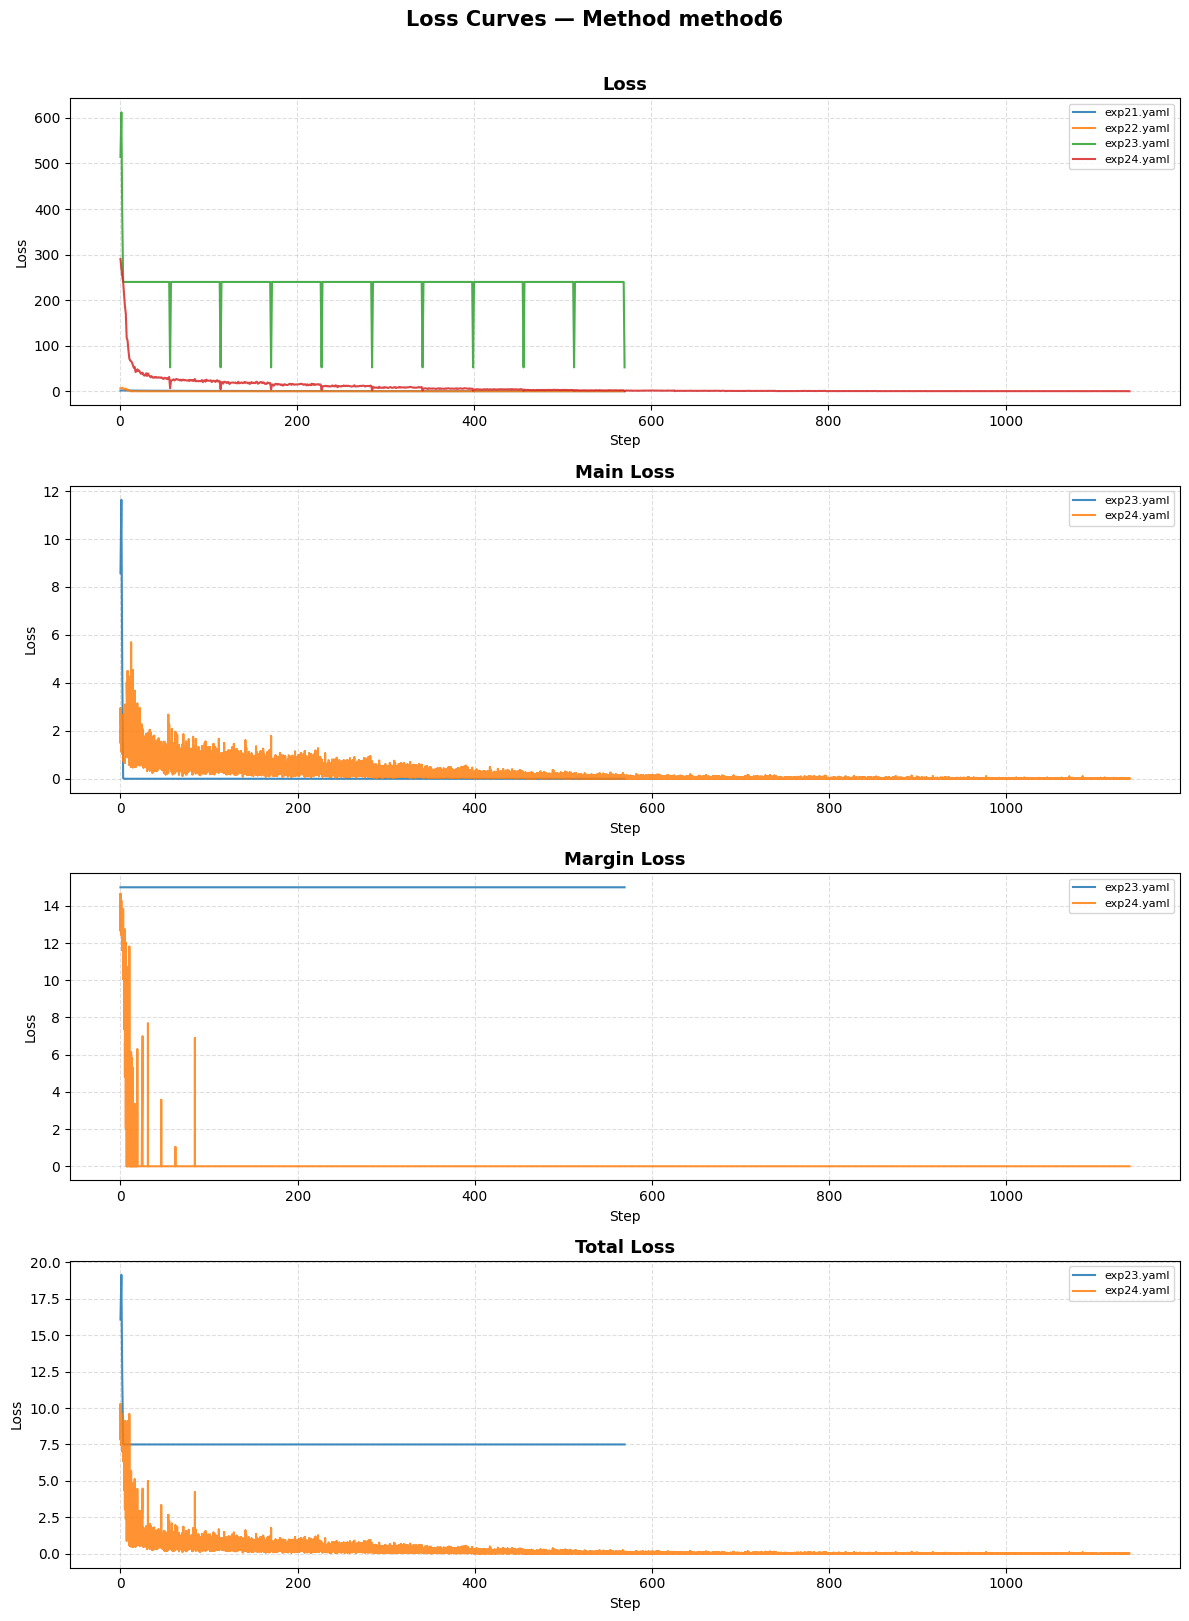


Ringkasan Loss:
experiment   loss_type       min        max       mean         final  n_steps
exp21.yaml        loss  0.194220   1.852246   0.510509  2.480094e-01      570
exp22.yaml        loss  0.000000   7.938798   0.093636  1.192093e-07      570
exp23.yaml        loss 52.500000 612.423218 238.103661  5.250000e+01      570
exp24.yaml        loss  0.055292 290.442932   8.062311  5.584546e-02     1140
exp23.yaml   main_loss -0.000000  11.638226   0.044140 -0.000000e+00    17990
exp24.yaml   main_loss  0.000764   5.685763   0.216605  1.174349e-02    35980
exp23.yaml margin_loss 15.000000  15.000000  15.000000  1.500000e+01    17990
exp24.yaml margin_loss  0.000000  14.652477   0.077687  0.000000e+00    35980
exp23.yaml  total_loss  7.500000  19.138226   7.544140  7.500000e+00    17990
exp24.yaml  total_loss  0.000764  10.269611   0.255448  1.174349e-02    35980


,experiment,loss_type,min,max,mean,final,n_steps
0,exp21.yaml,loss,0.194220,1.852246,0.510509,2.480094e-01,570
1,exp22.yaml,loss,0.000000,7.938798,0.093636,1.192093e-07,570
2,exp23.yaml,loss,52.500000,612.423218,238.103661,5.250000e+01,570
3,exp24.yaml,loss,0.055292,290.442932,8.062311,5.584546e-02,1140
4,exp23.yaml,main_loss,-0.000000,11.638226,0.044140,-0.000000e+00,17990
5,exp24.yaml,main_loss,0.000764,5.685763,0.216605,1.174349e-02,35980
6,exp23.yaml,margin_loss,15.000000,15.000000,15.000000,1.500000e+01,17990
7,exp24.yaml,margin_loss,0.000000,14.652477,0.077687,0.000000e+00,35980
8,exp23.yaml,total_loss,7.500000,19.138226,7.544140,7.500000e+00,17990
9,exp24.yaml,total_loss,0.000764,10.269611,0.255448,1.174349e-02,35980


In [31]:
plot_all_losses("method6")

In [1]:
import json
import yaml
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path
from statistics import mean
import pandas as pd
from transformers.trainer_utils import get_last_checkpoint

def load_yaml(path):
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File tidak ditemukan: {filepath}")
    with open(filepath, "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}

def load_json(path):
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File JSON tidak ditemukan: {filepath}")
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

def get_loss_file(method_num: int, folder: str) -> Path:
    """Ambil trainer_state.json dari checkpoint terakhir."""
    output_dir = Path(f"{method_num}_outputs") / folder / "outputs"
    
    last_checkpoint = get_last_checkpoint(str(output_dir))
    
    if last_checkpoint:
        loss_file = Path(last_checkpoint) / "trainer_state.json"
    else:
        loss_file = output_dir / "trainer_state.json"
    
    return loss_file

def extract_loss_from_trainer_state(trainer_state: dict) -> dict:
    """
    Ekstrak semua jenis loss dari log_history di trainer_state.json.
    Mengembalikan dict berisi {loss_type: [(step, value), ...]}
    """
    log_history = trainer_state.get("log_history", [])
    if log_history:
        print(log_history[0])
        
    loss_series = {}

    for entry in log_history:
        step = entry.get("step")
        if step is None:
            continue
            
        for key, value in entry.items():
            if "loss" in key.lower():
                if value is None:
                    value = 0.0
                if isinstance(value, (int, float)):
                    # Mengubah nama label main_loss menjadi mle_loss
                    actual_key = "mle_loss" if key.lower() == "main_loss" else key
                    loss_series.setdefault(actual_key, []).append((step, float(value)))

    return loss_series

def plot_all_losses(method_num: int, save_path: str = "loss_plot.png"):
    method_cfg = load_yaml(f"configs/methods/{method_num}.yaml")
    experiments = method_cfg.get("experiments", [])

    folder_map = {}
    for exp in experiments:
        exp_code = exp.get("code")
        if exp_code:
            exp_cfg = load_yaml(f"configs/experiments/{exp_code}")
            output_name = exp_cfg.get("output_name")
            label = exp_cfg.get("label", exp_code)
            if output_name:
                folder_map[output_name] = label

    raw_data = {}
    exp_max_steps = {}

    for folder, label in folder_map.items():
        loss_file = get_loss_file(method_num, folder)
        print(f"Membaca: {loss_file}")
        if not loss_file.is_file():
            print(f"  [SKIP] File tidak ditemukan.")
            continue

        trainer_state = load_json(loss_file)
        loss_series = extract_loss_from_trainer_state(trainer_state)
        
        raw_data[label] = loss_series
        
        m_step = 0
        for vals in loss_series.values():
            if vals:
                m_step = max(m_step, max(s for s, v in vals))
        exp_max_steps[label] = m_step

    if not raw_data:
        print("Tidak ada data loss yang ditemukan.")
        return

    all_data = {}
    labels = list(raw_data.keys())

    if len(labels) >= 4:
        l1, l2, l3, l4 = labels[:4]

        # Kumpulkan semua tipe loss dari seluruh eksperimen secara global
        all_loss_types = set()
        for series in raw_data.values():
            all_loss_types.update(series.keys())

        # Kumpulkan step unik dari tiap eksperimen untuk memetakan nilai 0.0 jika data kosong
        exp_steps = {}
        for lbl in labels:
            steps = set()
            for vals in raw_data.get(lbl, {}).values():
                steps.update(s for s, _ in vals)
            exp_steps[lbl] = sorted(list(steps))
            if not exp_steps[lbl]:
                max_st = exp_max_steps.get(lbl, 0)
                exp_steps[lbl] = [0, max_st] if max_st > 0 else [0]

        def merge_exp(base_lbl, append_lbl, new_lbl):
            base_max_step = exp_max_steps.get(base_lbl, 0)
            b_steps = exp_steps[base_lbl]
            a_steps = exp_steps[append_lbl]
            
            for lt in all_loss_types:
                s1 = raw_data.get(base_lbl, {}).get(lt, [])
                s2 = raw_data.get(append_lbl, {}).get(lt, [])
                
                # Set loss jadi 0 jika tipe ini tidak ditemukan di eksperimen pertama (base)
                if not s1:
                    s1 = [(s, 0.0) for s in b_steps]
                
                # Set loss jadi 0 jika tipe ini tidak ditemukan di eksperimen kedua (append)
                if not s2:
                    s2 = [(s, 0.0) for s in a_steps]
                
                # Shift step untuk eksperimen lanjutan
                s2_shifted = []
                if s2:
                    min_step_2 = min(s for s, v in s2)
                    shift = base_max_step if (min_step_2 <= base_max_step and base_max_step > 0) else 0
                    for s, v in s2:
                        s2_shifted.append((s + shift, v))
                    
                all_data[(new_lbl, lt)] = sorted(s1 + s2_shifted, key=lambda x: x[0])

        # 1. Eksperimen 1 + Eksperimen 2 -> finetune
        merge_exp(l1, l2, "finetune")
        
        # 2. Eksperimen 1 + Eksperimen 3 -> margin half
        merge_exp(l1, l3, "margin half")
        
        # 3. Eksperimen 4 -> margin full
        a_steps_4 = exp_steps[l4]
        for lt in all_loss_types:
            s4 = raw_data.get(l4, {}).get(lt, [])
            if not s4:
                s4 = [(s, 0.0) for s in a_steps_4]
            all_data[("margin full", lt)] = s4
            
    else:
        for label, series in raw_data.items():
            for lt, vals in series.items():
                all_data[(label, lt)] = vals

    # ── Plot ──────────────────────────────────────────────────────────────────
    loss_types = sorted(set(lt for _, lt in all_data.keys()))
    if not loss_types:
        print("Tidak ada titik plot untuk divisualisasikan.")
        return

    n_plots = len(loss_types)
    fig, axes = plt.subplots(n_plots, 1, figsize=(8, 4 * n_plots), squeeze=False)
    colors = cm.tab10.colors

    for ax_idx, loss_type in enumerate(loss_types):
        ax = axes[ax_idx][0]
        color_idx = 0

        for (label, lt), values in sorted(all_data.items()):
            if lt != loss_type:
                continue
            if not values:
                continue
            steps, losses = zip(*values)
            ax.plot(steps, losses,
                    label=label,
                    color=colors[color_idx % len(colors)],
                    linewidth=1.5,
                    alpha=0.85)
            color_idx += 1

        # Mengubah penulisan judul khusus untuk mle_loss menjadi kapital (MLE Loss)
        title_text = "MLE Loss" if loss_type == "mle_loss" else loss_type.replace("_", " ").title()
        ax.set_title(title_text, fontsize=13, fontweight="bold")
        ax.set_xlabel("Step")
        ax.set_ylabel("Loss")
        ax.legend(loc="upper right", fontsize=8)
        ax.grid(True, linestyle="--", alpha=0.4)

    fig.suptitle(f"Loss Curves — Method {method_num}", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches="tight", dpi=150)
    print(f"\nPlot disimpan ke: {save_path}")
    plt.show()

    # ── Ringkasan DataFrame ───────────────────────────────────────────────────
    rows = []
    for (label, loss_type), values in all_data.items():
        if not values:
            continue
        _, losses = zip(*values)
        rows.append({
            "experiment": label,
            "loss_type": loss_type,
            "min": min(losses),
            "max": max(losses),
            "mean": mean(losses),
            "final": losses[-1],
            "n_steps": len(losses),
        })

    df = pd.DataFrame(rows).sort_values(["loss_type", "experiment"]).reset_index(drop=True)
    print("\nRingkasan Loss:")
    print(df.to_string(index=False))
    return df

/home/qiscus/Coresearch_ITB_Qiscus/repo_alan/SLM Summarization/symbolic_distill_contrastive_summ/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Membaca: method6_outputs/qwen_5_warmup/outputs/checkpoint-570/trainer_state.json
{'epoch': 0.017787659811006114, 'grad_norm': 17.125, 'learning_rate': 0.0, 'loss': 1.7111334800720215, 'step': 1}
Membaca: method6_outputs/qwen_5_finetune/outputs/checkpoint-570/trainer_state.json
{'epoch': 0.017787659811006114, 'grad_norm': 28928.0, 'learning_rate': 0.0, 'loss': 9.639596939086914, 'step': 1}
Membaca: method6_outputs/qwen_5_margin_part/outputs/checkpoint-570/trainer_state.json
{'epoch': 0, 'main_loss': 1.1248804330825806, 'margin_loss': 11.482182502746582, 'max_neg': -4.642697811126709, 'min_pos': -1.1248804330825806, 'step': 0, 'total_loss': 6.865971565246582}
Membaca: method6_outputs/qwen_5_margin_full/outputs/checkpoint-1140/trainer_state.json
{'epoch': 0, 'main_loss': 2.0551223754882812, 'margin_loss': 13.452190399169922, 'max_neg': -3.602931499481201, 'min_pos': -2.0551223754882812, 'step': 0, 'total_loss': 8.781217575073242}

Plot disimpan ke: loss_plot.png


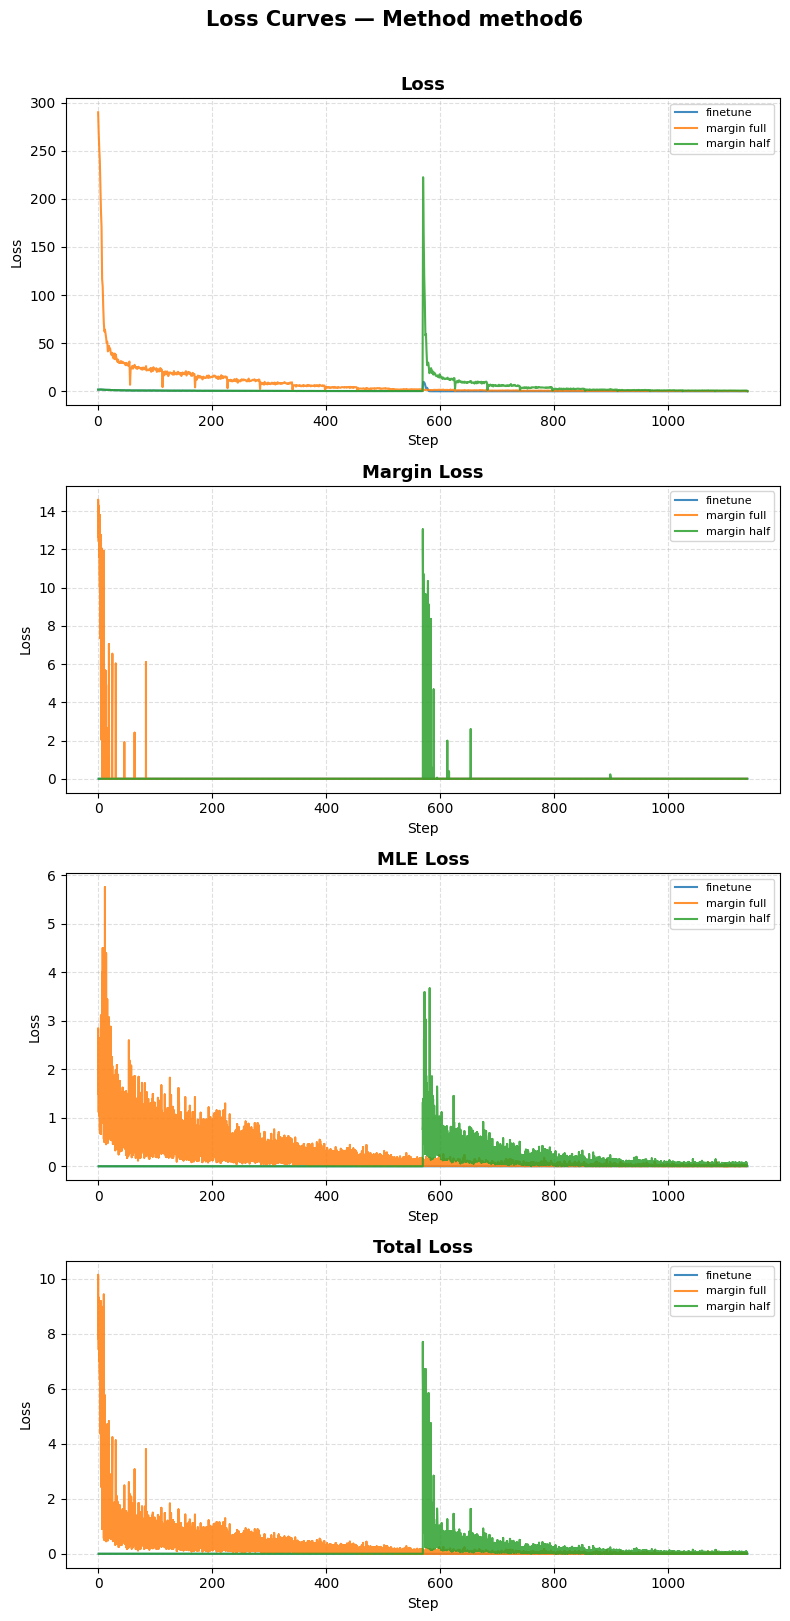


Ringkasan Loss:
 experiment   loss_type      min        max     mean        final  n_steps
   finetune        loss 0.000000   9.639597 0.297441 1.192093e-07     1140
margin full        loss 0.050832 290.027039 7.970309 5.446153e-02     1140
margin half        loss 0.146651 222.521927 2.949295 1.466507e-01     1140
   finetune margin_loss 0.000000   0.000000 0.000000 0.000000e+00     1140
margin full margin_loss 0.000000  14.592751 0.076875 0.000000e+00    35980
margin half margin_loss 0.000000  13.045880 0.055017 0.000000e+00    18560
   finetune    mle_loss 0.000000   0.000000 0.000000 0.000000e+00     1140
margin full    mle_loss 0.000938   5.753465 0.214096 1.572420e-02    35980
margin half    mle_loss 0.000000   3.669646 0.138392 1.149206e-02    18560
   finetune  total_loss 0.000000   0.000000 0.000000 0.000000e+00     1140
margin full  total_loss 0.000938  10.137278 0.252533 1.572420e-02    35980
margin half  total_loss 0.000000   7.698892 0.165900 1.149206e-02    18560


,experiment,loss_type,min,max,mean,final,n_steps
0,finetune,loss,0.000000,9.639597,0.297441,1.192093e-07,1140
1,margin full,loss,0.050832,290.027039,7.970309,5.446153e-02,1140
2,margin half,loss,0.146651,222.521927,2.949295,1.466507e-01,1140
3,finetune,margin_loss,0.000000,0.000000,0.000000,0.000000e+00,1140
4,margin full,margin_loss,0.000000,14.592751,0.076875,0.000000e+00,35980
5,margin half,margin_loss,0.000000,13.045880,0.055017,0.000000e+00,18560
6,finetune,mle_loss,0.000000,0.000000,0.000000,0.000000e+00,1140
7,margin full,mle_loss,0.000938,5.753465,0.214096,1.572420e-02,35980
8,margin half,mle_loss,0.000000,3.669646,0.138392,1.149206e-02,18560
9,finetune,total_loss,0.000000,0.000000,0.000000,0.000000e+00,1140


In [2]:
plot_all_losses("method6")